In [ ]:
from google.colab import files
df = pd.read_excel('python_data.xlsx')
import pandas as pd
df1=pd.read_excel('python_data.xlsx','StatewiseTestingDetails')
df1.fillna(0, inplace=True)
df1

,Date,State,TotalSamples,Negative,Positive
0,2020-04-17,Andaman and Nicobar Islands,1403,1210,12.0
1,2020-04-24,Andaman and Nicobar Islands,2679,0,27.0
2,2020-04-27,Andaman and Nicobar Islands,2848,0,33.0
3,2020-05-01,Andaman and Nicobar Islands,3754,0,33.0
4,2020-05-16,Andaman and Nicobar Islands,6677,0,33.0
...,...,...,...,...,...
16331,2021-08-06,West Bengal,15999961,0,0.0
16332,2021-08-07,West Bengal,16045662,0,0.0
16333,2021-08-08,West Bengal,16092192,0,0.0
16334,2021-08-09,West Bengal,16122345,0,0.0


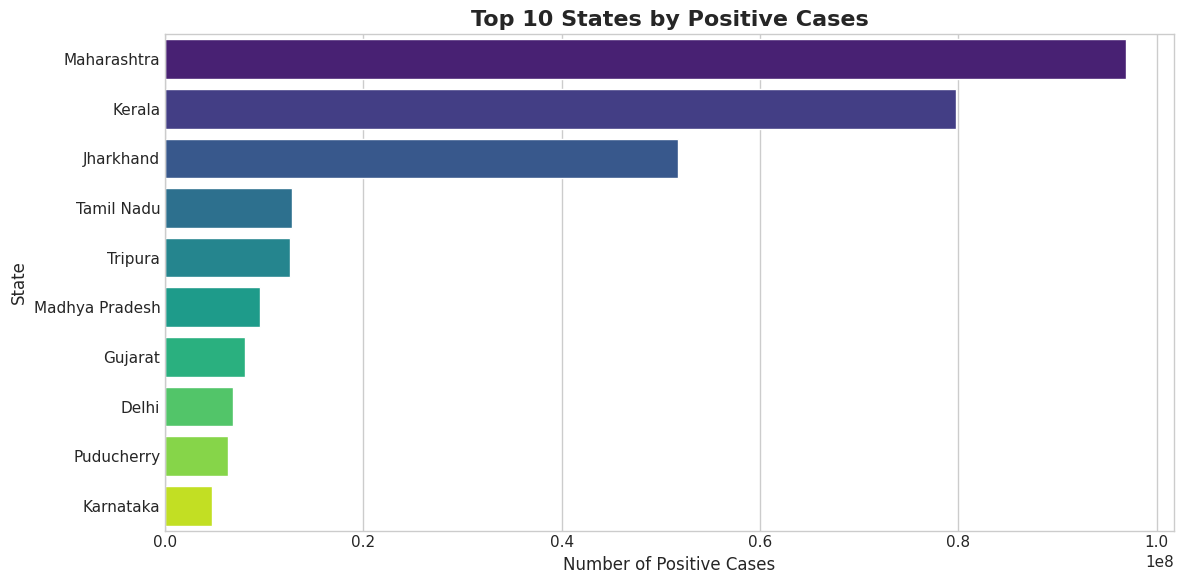

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Count positive cases per state
state_positive = df1.groupby("State")["Positive"].sum().reset_index()
state_positive.columns = ["State", "PositiveCases"]

# Sort values
state_positive = state_positive.sort_values(by="PositiveCases", ascending=False)

# Create the barplot
plt.figure(figsize=(12, 6))
barplot = sns.barplot(
    data=state_positive.head(10),
    x="PositiveCases",
    y="State"
)

# Apply viridis color manually
viridis_colors = sns.color_palette("viridis", 10)
for patch, color in zip(barplot.patches, viridis_colors):
    patch.set_facecolor(color)

# Labels and title
plt.title("Top 10 States by Positive Cases", fontsize=16, fontweight='bold')
plt.xlabel("Number of Positive Cases", fontsize=12)
plt.ylabel("State", fontsize=12)

plt.tight_layout()
plt.show()


In [ ]:
df2=pd.read_excel('python_data.xlsx','state data')
df2.fillna(0, inplace=True)
df2

,S. No.,Name of State / UT,Active Cases,Cured/Discharged/Migrated,Deaths,Total Confirmed cases
0,1,Andaman and Nicobar,4,7408,129,7541
1,2,Andhra Pradesh,20593,1944267,13490,1978350
2,3,Arunachal Pradesh,3032,46399,237,49668
3,4,Assam,11719,555470,5357,572546
4,5,Bihar,357,715119,9646,725122
5,6,Chandigarh,27,61132,811,61970
6,7,Chhattisgarh,1780,987642,13536,1002958
7,8,Dadra and Nagar Haveli and Daman and Diu,12,10636,4,10652
8,9,Delhi,516,1411042,25065,1436623
9,10,Goa,992,167556,3157,171705


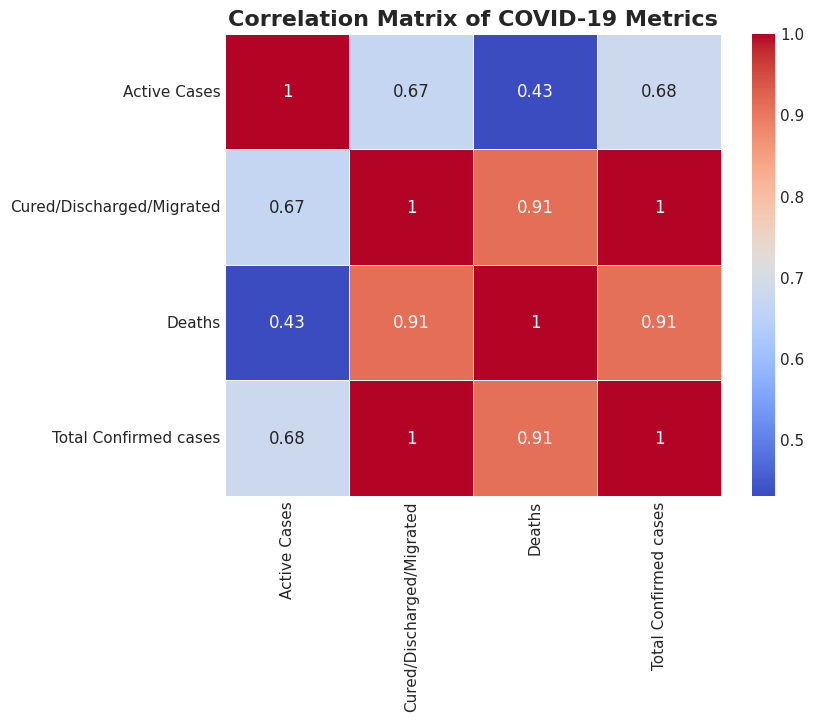

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
#Heatmap: Correlation of Case Metrics
corr_df = df2[['Active Cases', 'Cured/Discharged/Migrated', 'Deaths', 'Total Confirmed cases']]
plt.figure(figsize=(8, 6))
sns.heatmap(corr_df.corr(), annot=True, cmap='coolwarm', linewidths=.5)
plt.title('Correlation Matrix of COVID-19 Metrics', fontsize=16, fontweight='bold')
plt.show()

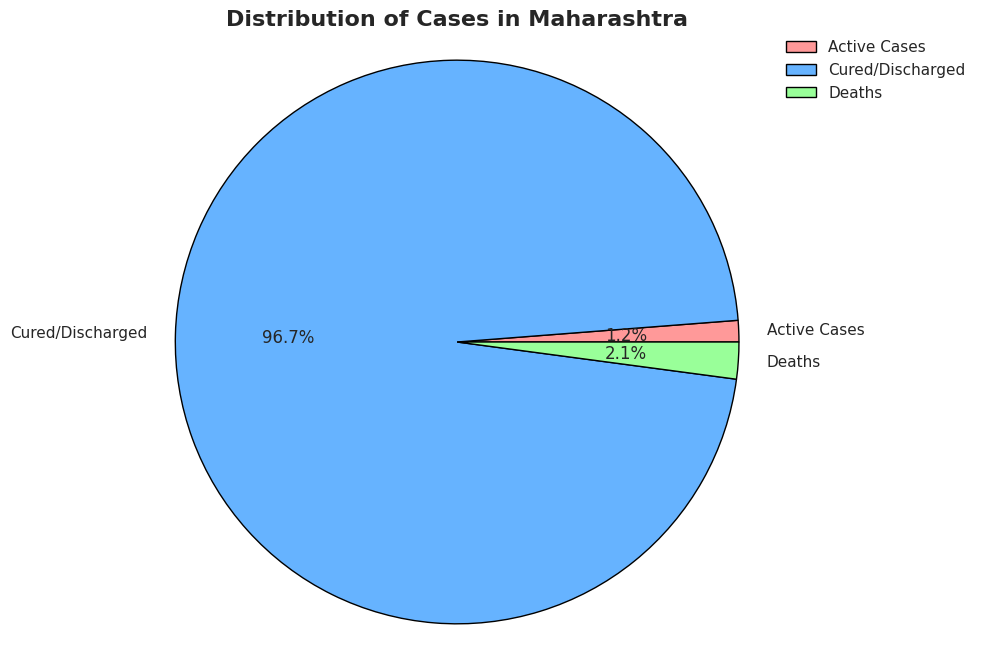

In [ ]:
# Pie chart: Distribution of Cases (Active, Cured, Deaths) for Maharashtra
maharashtra_data = df2[df2['Name of State / UT'] == 'Maharashtra']
if not maharashtra_data.empty:
    labels = ['Active Cases', 'Cured/Discharged', 'Deaths']
    sizes = [maharashtra_data['Active Cases'].iloc[0],
             maharashtra_data['Cured/Discharged/Migrated'].iloc[0],
             maharashtra_data['Deaths'].iloc[0]]
    colors = ['#ff9999', '#66b3ff', '#99ff99']

    plt.figure(figsize=(8, 8))
    plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, wedgeprops={'edgecolor': 'black'})
    plt.title('Distribution of Cases in Maharashtra', fontsize=16, fontweight='bold')
   #place legend in center right of plot
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
    plt.axis('equal')
    plt.show()

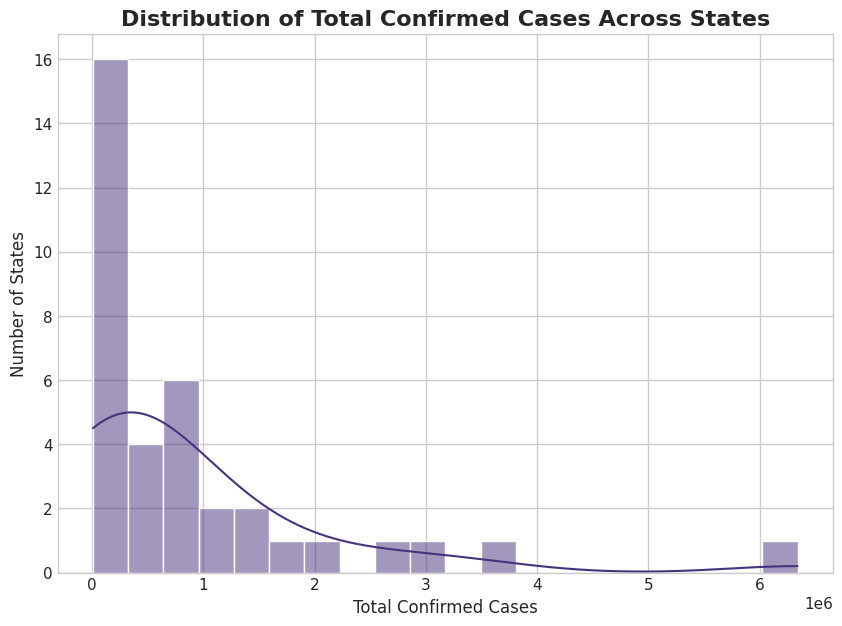

In [ ]:
#Histogram: Distribution of Total Confirmed Cases
plt.figure(figsize=(10, 7))
sns.histplot(df2['Total Confirmed cases'], bins=20, kde=True)
plt.title('Distribution of Total Confirmed Cases Across States', fontsize=16, fontweight='bold')
plt.xlabel('Total Confirmed Cases')
plt.ylabel('Number of States')
plt.show()

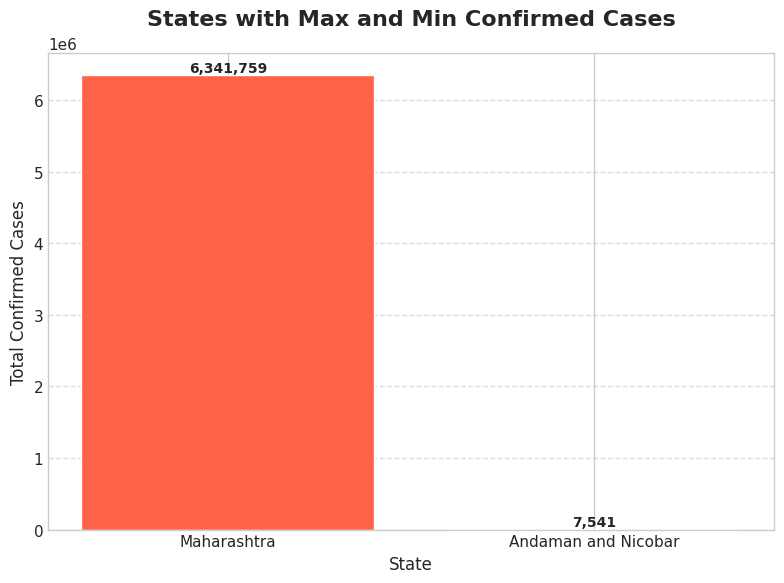

In [ ]:
# Rename columns for easier access and consistency
df2 = df2.rename(columns={
    'Name of State / UT': 'State',
    'Total Confirmed cases': 'Total Confirmed',
    'Cured/Discharged/Migrated': 'Cured',
    'Deaths': 'Deaths'
})
sns.set_style("whitegrid")
sns.set_palette("viridis")


# Get the states with max and min values for all three metrics
max_cases_state = df2.loc[df2['Total Confirmed'].idxmax()]
min_cases_state = df2.loc[df2['Total Confirmed'].idxmin()]


# --- Visualization 1: Bar Chart for Total Confirmed Cases ---

case_data = pd.DataFrame({
    'State': [max_cases_state['State'], min_cases_state['State']],
    'Cases': [max_cases_state['Total Confirmed'], min_cases_state['Total Confirmed']]
})

plt.figure(figsize=(8, 6))
bars = plt.bar(case_data['State'], case_data['Cases'], color=['#FF6347', '#4682B4'])
plt.title('States with Max and Min Confirmed Cases', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('State')
plt.ylabel('Total Confirmed Cases')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=0)

# Add value labels on top of the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, f'{yval:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

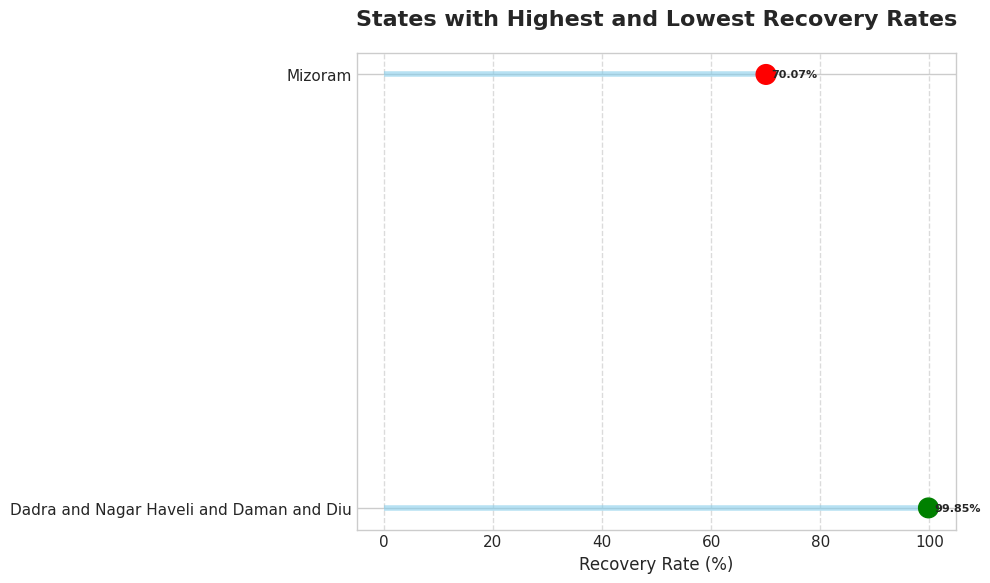

In [ ]:
# Calculate Recovery Rate
df2['Recovery Rate (%)'] = (df2['Cured'] / df2['Total Confirmed']) * 100

max_recovery_state = df2.loc[df2['Recovery Rate (%)'].idxmax()]
min_recovery_state = df2.loc[df2['Recovery Rate (%)'].idxmin()]

# --- Visualization 2: Lollipop Chart for Recovery Rate (%) ---

recovery_data = pd.DataFrame({
    'State': [max_recovery_state['State'], min_recovery_state['State']],
    'Recovery Rate': [max_recovery_state['Recovery Rate (%)'], min_recovery_state['Recovery Rate (%)']]
})

plt.figure(figsize=(10, 6))

# Use range(len()) for y-values (0 and 1), which is better for plotting
y_pos = range(len(recovery_data))

plt.hlines(y=y_pos, xmin=0, xmax=recovery_data['Recovery Rate'], color='skyblue', alpha=0.6, linewidth=4)
plt.scatter(recovery_data['Recovery Rate'], y_pos, color=['green', 'red'], s=200, zorder=3)

plt.title('States with Highest and Lowest Recovery Rates', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Recovery Rate (%)')
plt.ylabel('')

plt.yticks(y_pos, recovery_data['State'])  # Set the state names as y-axis ticks
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Add value labels to the right of the dots
for i, rate in enumerate(recovery_data['Recovery Rate']):
    plt.text(rate + 1, i, f"{rate:.2f}%", ha='left', va='center', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.show()

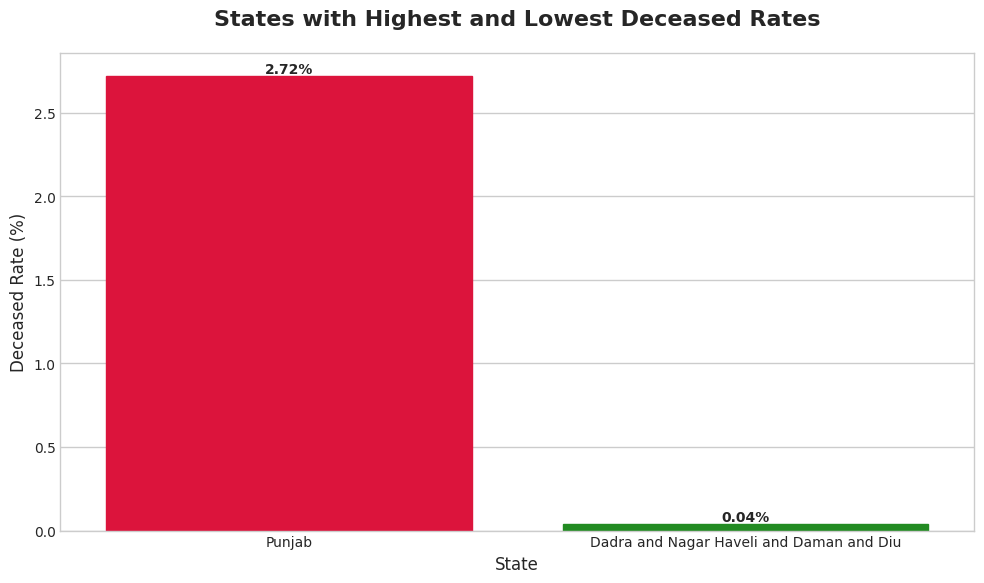

In [ ]:
# Calculate deceased rate
df2['Deceased Rate (%)'] = (df2['Deaths'] / df2['Total Confirmed']) * 100

# Get the states with max and min deceased rates
max_deceased_state = df2.loc[df2['Deceased Rate (%)'].idxmax()]
min_deceased_state = df2.loc[df2['Deceased Rate (%)'].idxmin()]

# Create a DataFrame for plotting
deceased_data = pd.DataFrame({
    'State': [max_deceased_state['State'], min_deceased_state['State']],
    'Deceased Rate': [max_deceased_state['Deceased Rate (%)'], min_deceased_state['Deceased Rate (%)']],
    'Color': ['#dc143c', '#228b22']  # crimson, forestgreen
})

# Plot
plt.figure(figsize=(10, 6))
bars = sns.barplot(
    data=deceased_data,
    x='State',
    y='Deceased Rate'
)

# Set individual colors without using palette
for bar, color in zip(bars.patches, deceased_data['Color']):
    bar.set_color(color)

plt.title('States with Highest and Lowest Deceased Rates', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('State', fontsize=12)
plt.ylabel('Deceased Rate (%)', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Add value labels on top of the bars
for index, row in deceased_data.iterrows():
    plt.text(
        index,
        row['Deceased Rate'],
        f"{row['Deceased Rate']:.2f}%",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


In [ ]:
df3=pd.read_excel('python_data.xlsx','staewise vaccine')
df3.fillna(0, inplace=True)
df3

,State/UTs,Total Vaccination Doses,Dose1,Dose 2,Dose 1 15-18,Dose 2 15-18,Dose 1 12-14,Dose 2 12-14,Precaution 18-59,Population
0,Andaman And Nicobar,991264,313284,320383,19208,18860,15124,14042,236936,399001
1,Andhra Pradesh,110957430,40645695,43555744,2535344,2527613,1523375,1495445,12054868,91702478
2,Arunachal Pradesh,1924584,861396,748505,59100,44869,40852,28445,81191,1711947
3,Assam,50335778,22550941,20575569,1262520,972402,999552,602283,2108179,35998752
4,Bihar,157293015,62956601,59160917,6240650,5348480,4288630,3403195,12022637,128500364
5,Chandigarh,2291937,1090035,921251,57708,43907,38210,26050,51034,1158040
6,Chhattisgarh,49167939,18956734,18537851,1234990,1053338,1076071,752571,5750424,32199722
7,Dadra And Nagar Haveli And Daman And Diu,1580060,730855,595090,31509,26943,19989,14929,138137,773997
8,Delhi,37409355,16605099,14356077,1008977,870793,683771,490644,2337340,19301096
9,Goa,2874477,1355046,1224544,51734,44551,33265,26640,61965,1521992


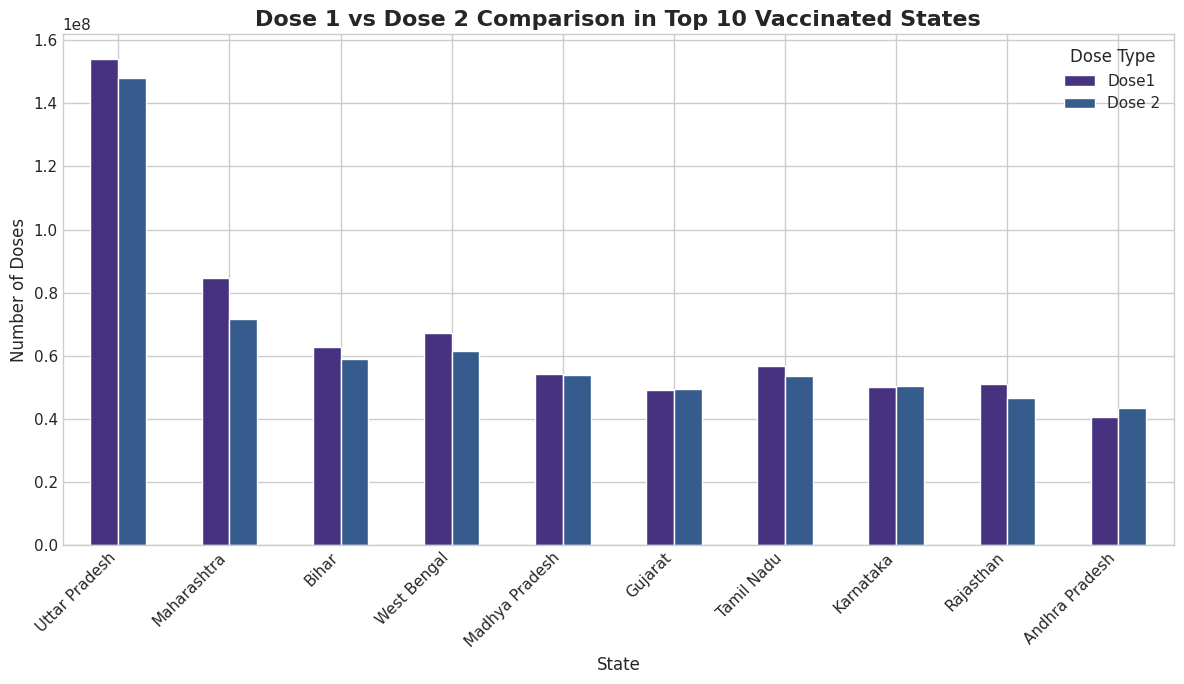

In [ ]:
#Bar chart: Comparison of Dose 1 vs Dose 2 vaccination for top 10 states
top_10_vaccine_comp = top_10_vaccine[['State/UTs', 'Dose1', 'Dose 2']]
top_10_vaccine_comp.set_index('State/UTs', inplace=True)
top_10_vaccine_comp.plot(kind='bar', figsize=(12, 7))
plt.title('Dose 1 vs Dose 2 Comparison in Top 10 Vaccinated States', fontsize=16, fontweight='bold')
plt.xlabel('State')
plt.ylabel('Number of Doses')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Dose Type')
plt.tight_layout()
plt.show()

In [ ]:
df4=pd.read_excel('python_data.xlsx','overall india')
df4.fillna(0, inplace=True)
df4

,Date,Date_YMD,Daily Confirmed,Daily Deceased
0,2020-01-30,2020-01-30,1,0
1,2020-01-31,2020-01-31,0,0
2,2020-02-01,2020-02-01,0,0
3,2020-02-02,2020-02-02,1,0
4,2020-02-03,2020-02-03,1,0
...,...,...,...,...
715,2022-01-14,2022-01-14,266518,621
716,2022-01-15,2022-01-15,271202,314
717,2022-01-16,2022-01-16,258089,385
718,2022-01-17,2022-01-17,238018,310


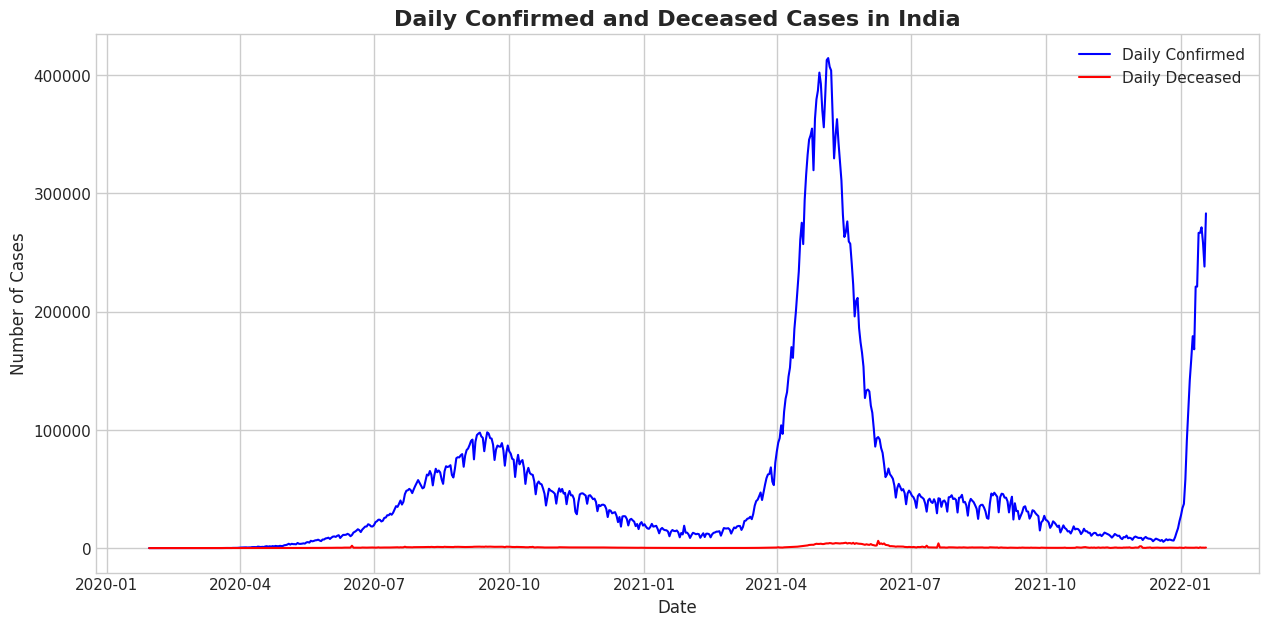

In [ ]:
#Line Chart: Daily Confirmed vs Daily Deceased
plt.figure(figsize=(15, 7))
sns.lineplot(data=df4, x='Date_YMD', y='Daily Confirmed', label='Daily Confirmed', color='blue')
sns.lineplot(data=df4, x='Date_YMD', y='Daily Deceased', label='Daily Deceased', color='red')
plt.title('Daily Confirmed and Deceased Cases in India', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Number of Cases')
plt.legend()
plt.grid(True)
plt.show()

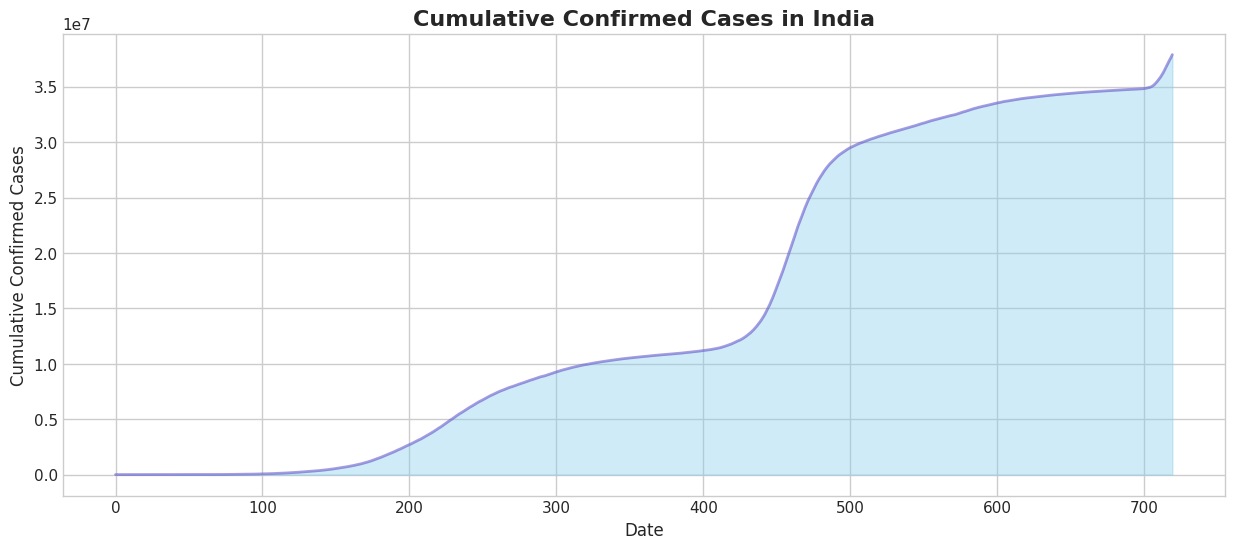

In [ ]:
#Area plot: Cumulative Confirmed Cases
plt.figure(figsize=(15, 6))
df4['Cumulative Confirmed'] = df4['Daily Confirmed'].cumsum()
plt.fill_between(df4.index, df4['Cumulative Confirmed'], color="skyblue", alpha=0.4)
plt.plot(df4.index, df4['Cumulative Confirmed'], color="Slateblue", alpha=0.6, linewidth=2)
plt.title('Cumulative Confirmed Cases in India', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Cumulative Confirmed Cases')
plt.grid(True)
plt.show()

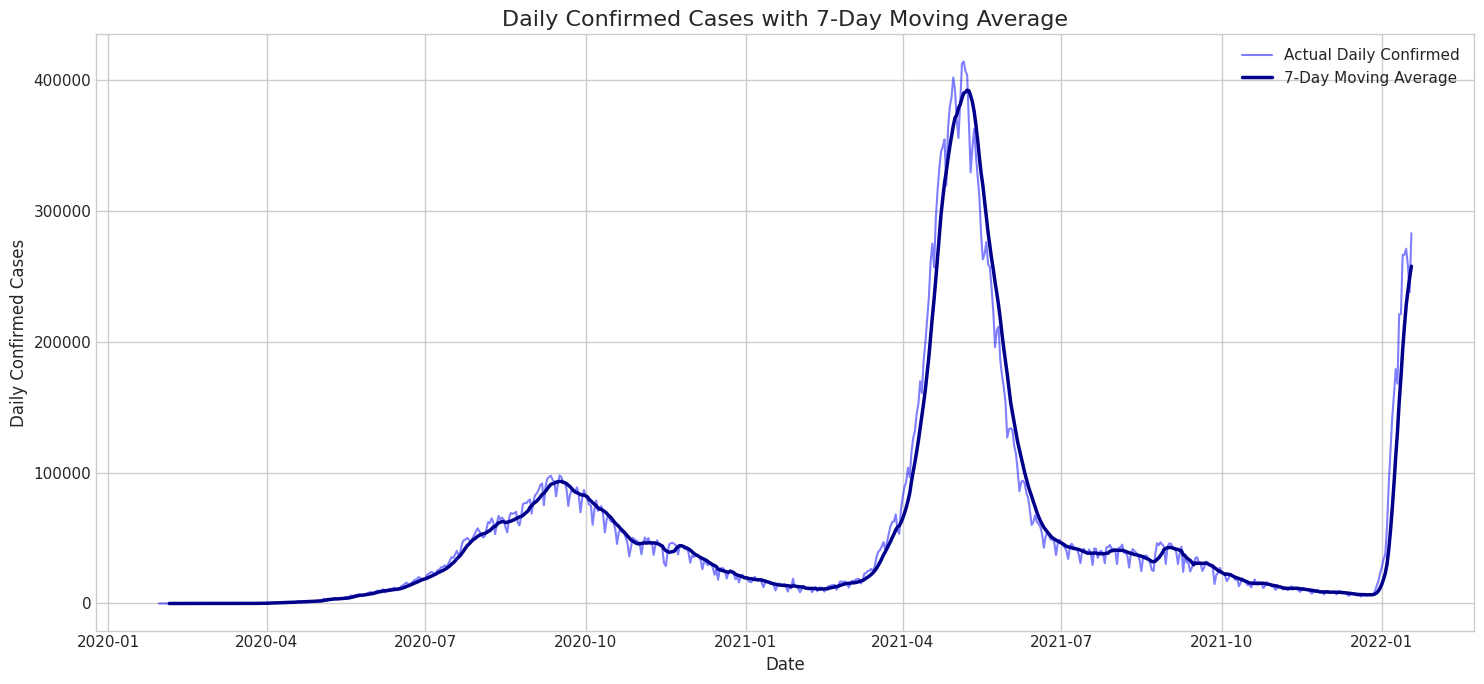

In [ ]:
#Moving average of daily confirmed cases to show trends
df4['Daily_Confirmed_MA7'] = df4['Daily Confirmed'].rolling(window=7).mean()
plt.figure(figsize=(15, 7))
sns.lineplot(data=df4, x='Date', y='Daily Confirmed', color='blue', alpha=0.5, label='Actual Daily Confirmed')
sns.lineplot(data=df4, x='Date', y='Daily_Confirmed_MA7', color='darkblue', linewidth=2.5, label='7-Day Moving Average')
plt.title('Daily Confirmed Cases with 7-Day Moving Average', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Daily Confirmed Cases', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
df5=pd.read_excel('python_data.xlsx','_statewise daily data')
df5.fillna(0, inplace=True)
df5

,Date,Date_YMD,Status,TT,AN,AP,AR,AS,BR,CH,...,PB,RJ,SK,TN,TG,TR,UP,UT,WB,UN
0,2020-03-14,2020-03-14,Confirmed,81,0,1,0,0,0,0,...,1,3,0,1,1,0,12,0,0,0
1,2020-03-14,2020-03-14,Recovered,9,0,0,0,0,0,0,...,0,1,0,0,0,0,4,0,0,0
2,2020-03-14,2020-03-14,Deceased,2,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2020-03-15,2020-03-15,Confirmed,27,0,0,0,0,0,0,...,0,1,0,0,2,0,1,0,0,0
4,2020-03-15,2020-03-15,Recovered,4,0,0,0,0,0,0,...,0,2,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1786,2021-10-30,2021-10-30,Recovered,14672,1,535,10,371,2,2,...,27,1,3,1172,191,8,9,6,880,0
1787,2021-10-30,2021-10-30,Deceased,445,0,2,0,4,0,0,...,1,0,0,14,1,0,0,0,13,0
1788,2021-10-31,2021-10-31,Confirmed,12907,0,385,1,212,8,5,...,26,2,21,1009,121,12,6,5,914,0
1789,2021-10-31,2021-10-31,Recovered,13152,0,675,9,236,9,3,...,25,2,8,1183,183,2,6,9,913,0


<Figure size 1500x700 with 0 Axes>

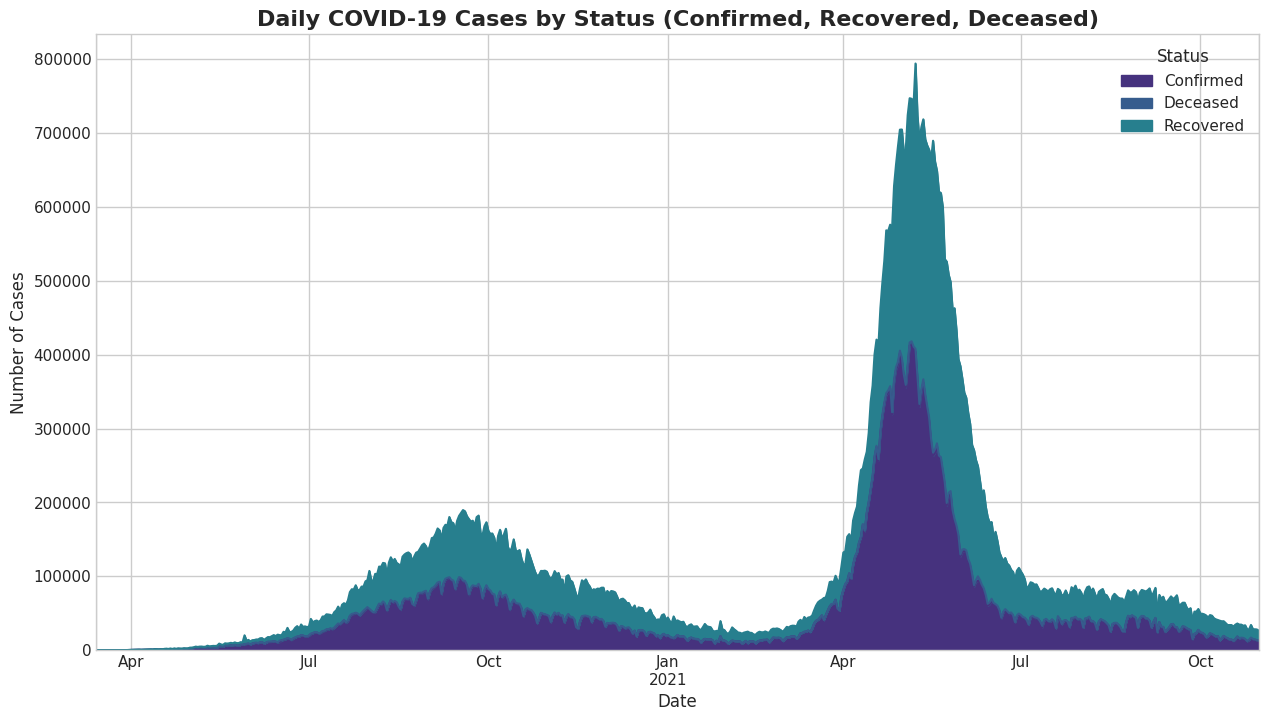

In [ ]:
#Stacked Area Chart: Daily Confirmed vs Recovered vs Deceased
# Pivot df5 to get daily confirmed, recovered, and deceased cases
daily_status_pivot = df5.pivot_table(index='Date_YMD', columns='Status', values='TT', aggfunc='sum')
plt.figure(figsize=(15, 7))
daily_status_pivot.plot.area(figsize=(15, 8), stacked=True)
plt.title('Daily COVID-19 Cases by Status (Confirmed, Recovered, Deceased)', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Number of Cases')
plt.legend(title='Status')
plt.show()

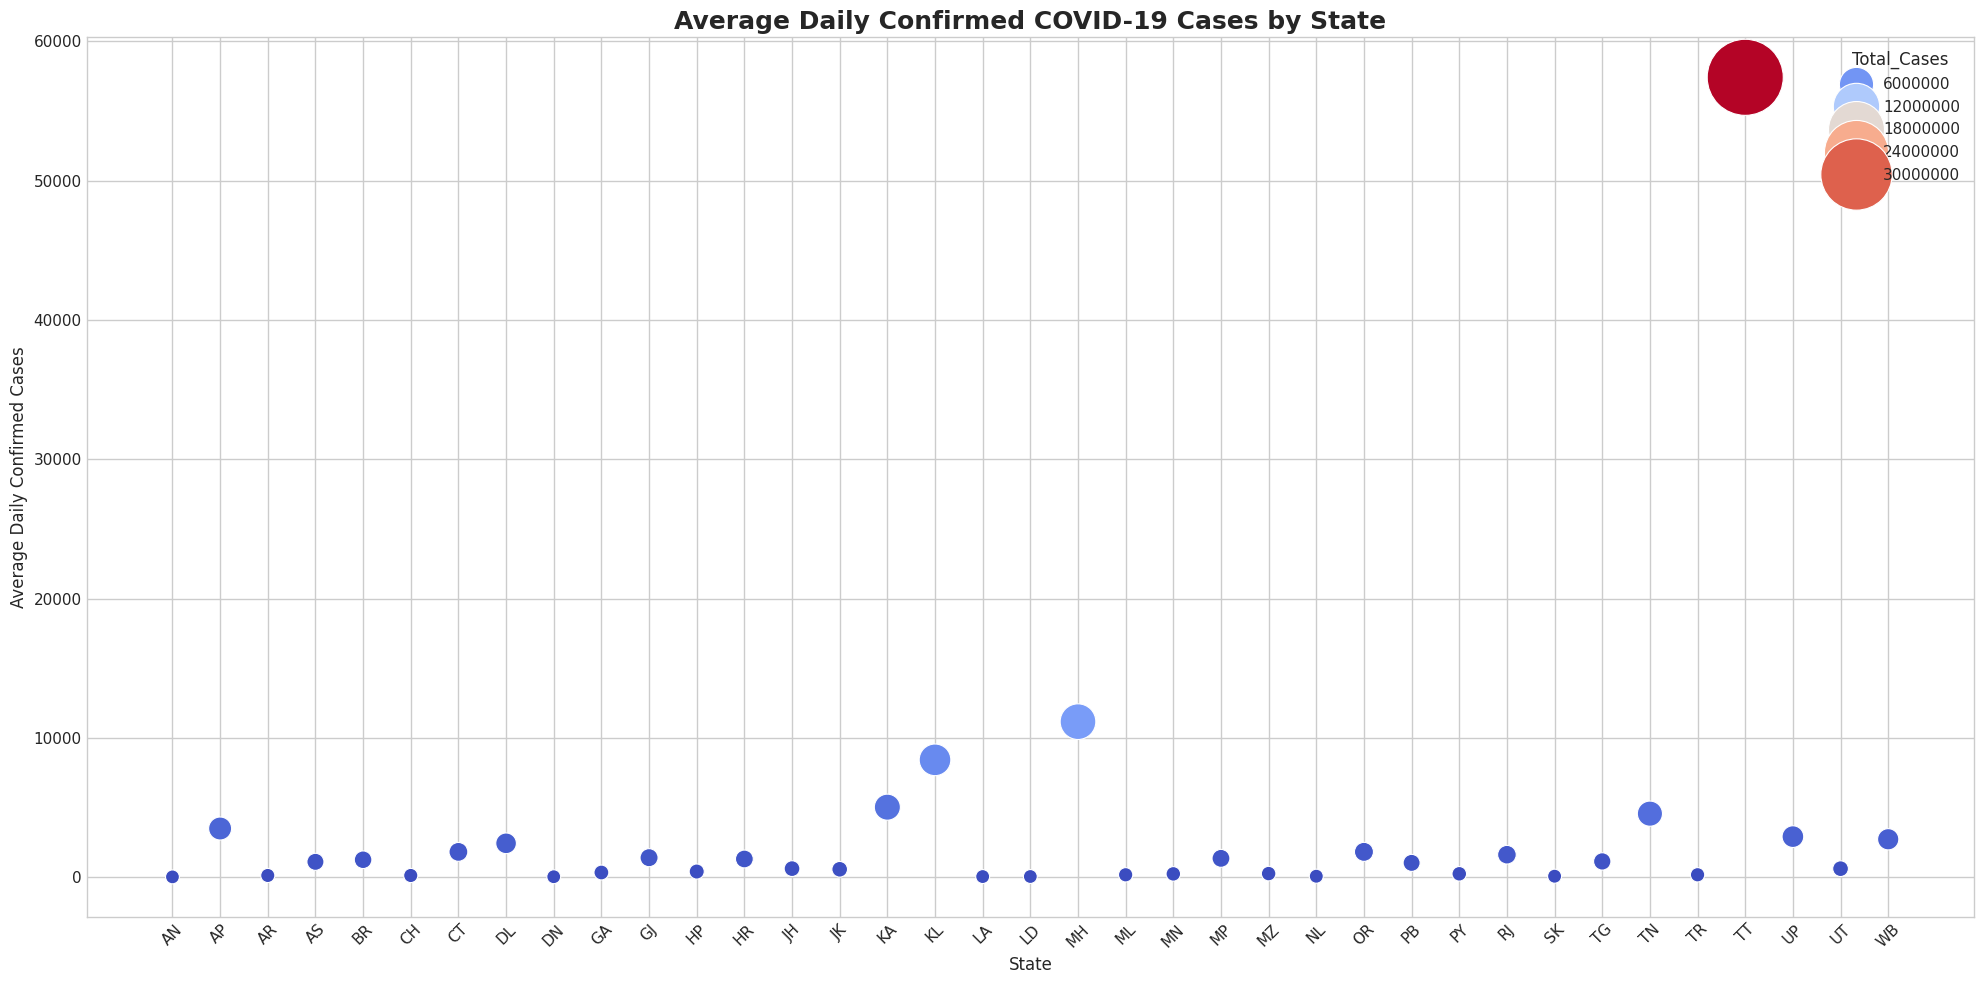

In [ ]:
# Melt the dataframe to long format
state_columns = df5.columns[3:-1]  # Exclude Date, Status, and 'TT' if at the end
melted_df = df5.melt(
    id_vars=['Date_YMD', 'Status'],
    value_vars=state_columns,
    var_name='State',
    value_name='Cases'
)

# Filter for confirmed cases only
confirmed_df = melted_df[(melted_df['Status'] == 'Confirmed') & (melted_df['Cases'] > 0)]

# Aggregate average and total cases per state
bubble_data = confirmed_df.groupby('State')['Cases'].agg(['mean', 'sum']).reset_index()
bubble_data.rename(columns={'mean': 'Average_Cases', 'sum': 'Total_Cases'}, inplace=True)

# Plot using seaborn
plt.figure(figsize=(20, 10))
sns.scatterplot(
    data=bubble_data,
    x='State',
    y='Average_Cases',
    size='Total_Cases',
    sizes=(100, 3000),  # Adjust size scale here
    hue='Total_Cases',
    palette='coolwarm',
    legend='brief'
)

plt.title('Average Daily Confirmed COVID-19 Cases by State', fontsize=18, fontweight='bold')
plt.xlabel('State')
plt.ylabel('Average Daily Confirmed Cases')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
df6=pd.read_excel('python_data.xlsx','Cleaned-Data')
df6.fillna(0, inplace=True)
df6

,Fever,Tiredness,Dry-Cough,Difficulty-in-Breathing,Sore-Throat,None_Sympton,Pains,Nasal-Congestion,Runny-Nose,Diarrhea,...,Gender_Male,Gender_Transgender,Severity_Mild,Severity_Moderate,Severity_None,Severity_Severe,Contact_Dont-Know,Contact_No,Contact_Yes,Country
0,1,1,1,1,1,0,1,1,1,1,...,1,0,1,0,0,0,0,0,1,China
1,1,1,1,1,1,0,1,1,1,1,...,1,0,1,0,0,0,0,1,0,China
2,1,1,1,1,1,0,1,1,1,1,...,1,0,1,0,0,0,1,0,0,China
3,1,1,1,1,1,0,1,1,1,1,...,1,0,0,1,0,0,0,0,1,China
4,1,1,1,1,1,0,1,1,1,1,...,1,0,0,1,0,0,0,1,0,China
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
316795,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,1,0,1,0,Other
316796,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,1,1,0,0,Other
316797,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,1,0,0,0,1,Other
316798,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,1,0,0,1,0,Other


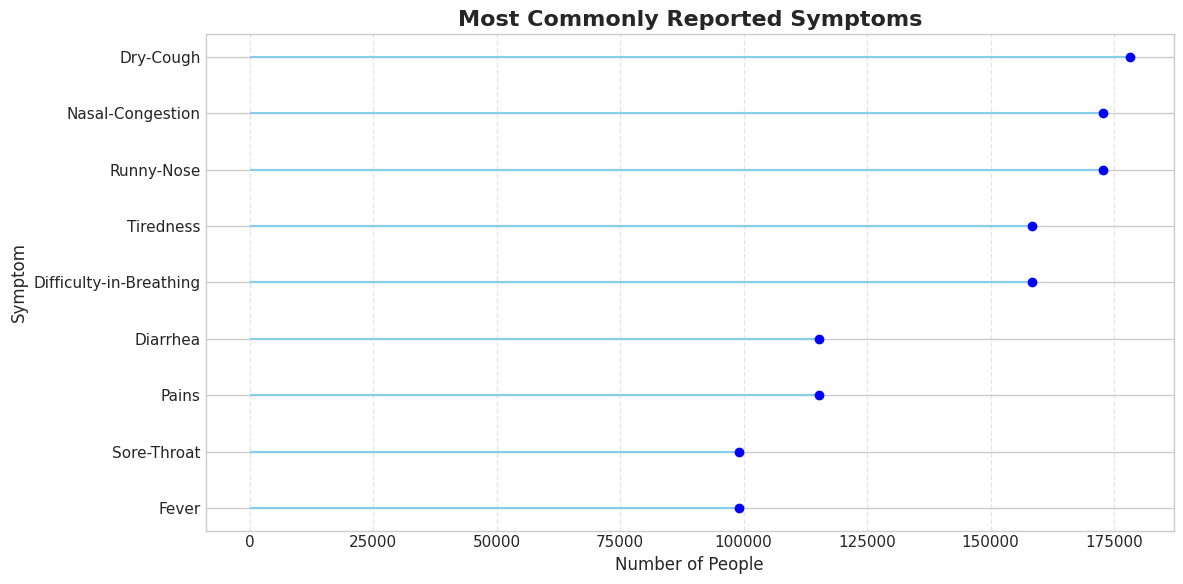

In [ ]:
plt.figure(figsize=(12, 6))
plt.hlines(y=data['Symptom'], xmin=0, xmax=data['Count'], color='skyblue')
plt.plot(data['Count'], data['Symptom'], "o", color='blue')

plt.title('Most Commonly Reported Symptoms', fontsize=16, fontweight='bold')
plt.xlabel('Number of People')
plt.ylabel('Symptom')
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

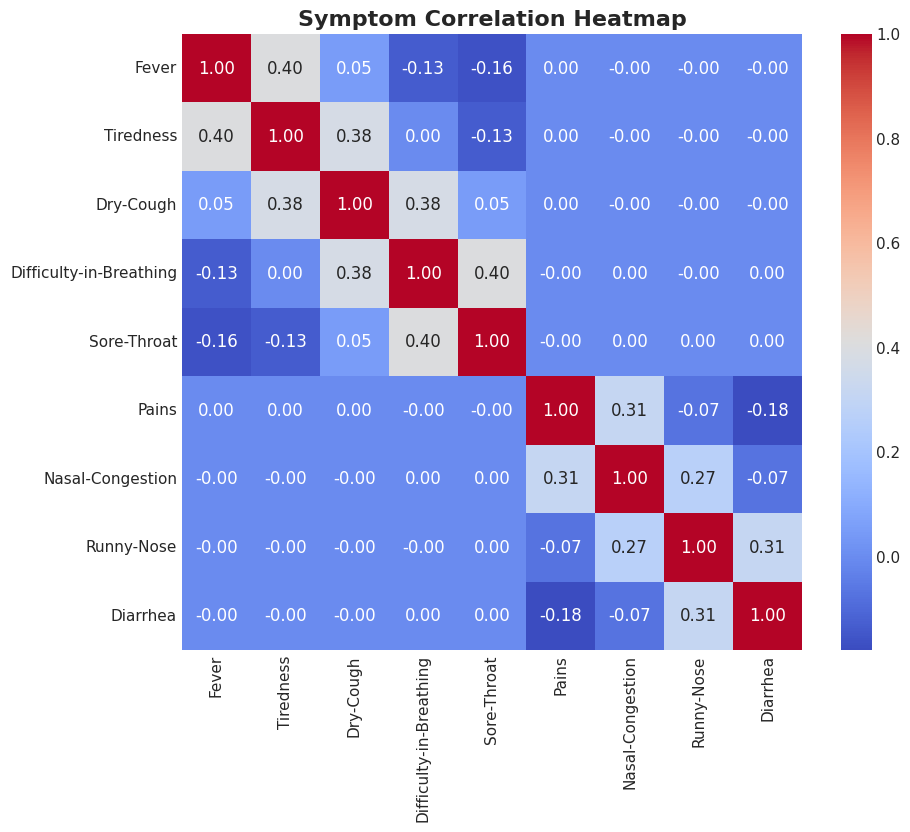

In [ ]:
#Heatmap: Symptom Correlation
# Select symptom columns and calculate the correlation matrix
symptoms = ['Fever', 'Tiredness', 'Dry-Cough', 'Difficulty-in-Breathing', 'Sore-Throat', 'Pains', 'Nasal-Congestion', 'Runny-Nose', 'Diarrhea']
correlation_matrix = df6[symptoms].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Symptom Correlation Heatmap', fontsize=16, fontweight='bold')
plt.show()